In [ ]:
#--- Common Lab Setup (run once per session)
import nltk, warnings
warnings.filterwarnings('ignore')
for pkg in ['punkt_tab', 'stopwords', 'wordnet', 'movie_reviews']:
  nltk.download(pkg, quiet=True)
print( 'NLP environment ready!')

NLP environment ready!


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
small = ['the battery is great and the camera is great',
         'the camera broke and the screen broke',
         'great battery great screen great phone']
cv = CountVectorizer()
X= cv.fit_transform(small)
dtm = pd.DataFrame(X.toarray(), columns=cv.get_feature_names_out(), index=['doc1', 'doc2', 'doc3'])
print ('Vocabulary:', list(cv.get_feature_names_out()))
dtm


Vocabulary: ['and', 'battery', 'broke', 'camera', 'great', 'is', 'phone', 'screen', 'the']


,and,battery,broke,camera,great,is,phone,screen,the
doc1,1,1,0,1,2,2,0,0,2
doc2,1,0,2,1,0,0,0,1,2
doc3,0,1,0,0,3,0,1,1,0


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
tf_small = TfidfVectorizer()
Xt = tf_small.fit_transform(small)
dtf = pd.DataFrame (Xt.toarray().round(2), columns=tf_small.get_feature_names_out(), index=['doc1', 'doc2', 'doc3'])
print ("'the' count in doc1:", dtm.loc['doc1', 'the'], '| TF-IDF:', dtf.loc['doc1', 'the'])
print("'broke' count in doc2:", dtm.loc ['doc2', 'broke'], '| TF-IDF:', dtf. loc['doc2', 'broke'], '(highest in its row)')
dtf


'the' count in doc1: 2 | TF-IDF: 0.47
'broke' count in doc2: 2 | TF-IDF: 0.7 (highest in its row)


,and,battery,broke,camera,great,is,phone,screen,the
doc1,0.24,0.24,0.0,0.24,0.47,0.62,0.00,0.00,0.47
doc2,0.27,0.00,0.7,0.27,0.00,0.00,0.00,0.27,0.54
doc3,0.00,0.28,0.0,0.00,0.84,0.00,0.37,0.28,0.00


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
try:
  from sklearn.datasets import fetch_20newsgroups
  cats = ['sci.space', 'rec.autos', 'comp.graphics', 'sci.med']
  news =  fetch_20newsgroups(subset = 'all', categories = cats, remove = ('headers', 'footers', 'quotes'))
  print(len(news.data), 'documents |', news.target_names)
  tfn = TfidfVectorizer(max_features=5000, stop_words = 'english')
  Xn = tfn.fit_transform(news.data); yn = news.target
  Xtr,Xte,ytr,yte = train_test_split(Xn, yn, test_size = 0.2, random_state=42, stratify=yn)
  nb = MultinomialNB().fit(Xtr, ytr)
  print('Test accuracy:', round(nb.score(Xte, yte), 3))
  sample = ['The rocket reached orbit after a flawless launch']
  print('Prediction:', news.target_names[nb.predict(tfn.transform(sample))[0]])
except Exception as e:
  print('Dataset download requires internet on first run - execute on your machine.')
  print('Expected: ~3900 documents, accuracy ~0.91, prediction sci.space  (', type(e).__name__,')')

3940 documents | ['comp.graphics', 'rec.autos', 'sci.med', 'sci.space']
Test accuracy: 0.885
Prediction: sci.space


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
try:
  pred = nb.predict(Xte)
  print(classification_report(yte, pred, target_names=news.target_names, digits=2))
  print(confusion_matrix(yte, pred))
except NameError:
  print('Run question 3 first (dataset download needed).')
  print('expected: every class F1>0.85; largest confusion between sci.med and sci.space.')

               precision    recall  f1-score   support

comp.graphics       0.86      0.92      0.89       195
    rec.autos       0.83      0.93      0.88       198
      sci.med       0.94      0.88      0.91       198
    sci.space       0.93      0.80      0.86       197

     accuracy                           0.88       788
    macro avg       0.89      0.88      0.88       788
 weighted avg       0.89      0.88      0.88       788

[[180  10   2   3]
 [  4 185   6   3]
 [ 11   7 174   6]
 [ 15  20   4 158]]


In [ ]:
pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 57.0 MB/s eta 0:00:00


In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
import nltk
nltk.download('movie_reviews')

[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!


True

In [ ]:
from nltk.corpus import movie_reviews
from gensim.models import Word2Vec
sents = []
for fid in movie_reviews.fileids()[:600]:
  for s in movie_reviews.sents(fid):
    toks = [w.lower() for w in s if w.isalpha()]
    if len(toks) > 3:
      sents.append(toks)
w2v = Word2Vec(sents, vector_size=100, window=5, min_count=5, seed=42, workers=1)
print('Sentences:', len(sents), '| Vocabulary:', len(w2v.wv))
print("most_similar('movie'):", [(w, round(s,3)) for w, s in w2v.wv.most_similar('movie', topn=4)])
print("similarity('good', 'great) =", round(w2v.wv.similarity('good', 'great'), 3))

Sentences: 18493 | Vocabulary: 6504
most_similar('movie'): [('film', 0.974), ('thing', 0.914), ('script', 0.909), ('fact', 0.903)]
similarity('good', 'great) = 0.784


variance explained: 88.7 %


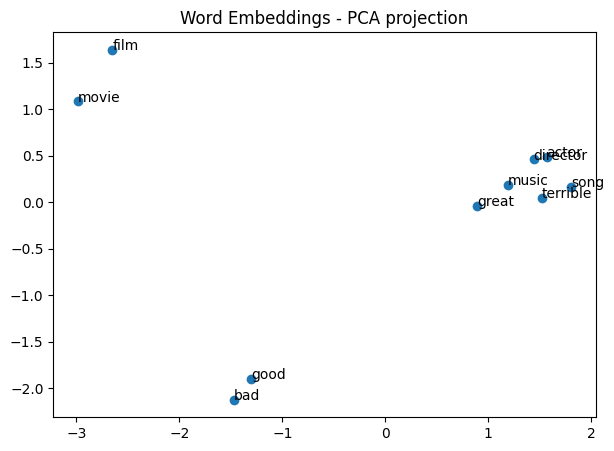

In [ ]:
%matplotlib inline
from sklearn.decomposition import PCA
import numpy as np, matplotlib.pyplot as plt
words = ['good','great','bad','terrible','film','movie','actor','director','music','song']
words = [w for w in words if w  in w2v.wv]
v = np.array([w2v.wv[w] for w in words])
p = PCA(n_components=2, random_state=42)
XY =  p.fit_transform(v)
print('variance explained:', round(p.explained_variance_ratio_.sum()*100, 1), '%')
plt.figure(figsize=(7, 5))
plt.scatter(XY[:,0],XY[:,1])
for w,(x, y) in zip(words, XY):
    plt.annotate(w, (x, y))
plt.title('Word Embeddings - PCA projection')
plt.show()